# Identity and PII Detection

This model predicts whether a document contains personally identifiable information (PII). Its output is binary: **PII detected** or **no PII detected**.

In [8]:
import json
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

In [9]:
with open("train.json", "r", encoding="utf-8") as file:
    records = json.load(file)

pii_df = pd.DataFrame(records)

In [10]:
print("Dataset shape:", pii_df.shape)
print("Columns:", pii_df.columns.tolist())
display(pii_df[["document", "full_text", "labels"]].head())

Dataset shape: (6807, 5)
Columns: ['document', 'full_text', 'tokens', 'trailing_whitespace', 'labels']


,document,full_text,labels
0,7,Design Thinking for innovation reflexion-Avril...,"[O, O, O, O, O, O, O, O, O, B-NAME_STUDENT, I-..."
1,10,Diego Estrada\n\nDesign Thinking Assignment\n\...,"[B-NAME_STUDENT, I-NAME_STUDENT, O, O, O, O, O..."
2,16,Reporting process\n\nby Gilberto Gamboa\n\nCha...,"[O, O, O, O, B-NAME_STUDENT, I-NAME_STUDENT, O..."
3,20,Design Thinking for Innovation\n\nSindy Samaca...,"[O, O, O, O, O, B-NAME_STUDENT, I-NAME_STUDENT..."
4,56,Assignment: Visualization Reflection Submitt...,"[O, O, O, O, O, O, O, O, O, O, O, O, B-NAME_ST..."


In [11]:

print("Missing values:")
print(pii_df[["full_text", "labels"]].isna().sum())

pii_df = pii_df.dropna(subset=["full_text", "labels"]).copy()
pii_df["full_text"] = pii_df["full_text"].astype(str)


Missing values:
full_text    0
labels       0
dtype: int64


## convert token-labels to PII label

In [12]:
def contains_pii(token_labels):
    for token_label in token_labels:
        if token_label != "O":
            return 1
    return 0


pii_df["has_pii"] = pii_df["labels"].apply(contains_pii)

print("Document-level label counts:")
print(pii_df["has_pii"].value_counts().sort_index())

Document-level label counts:
has_pii
0    5862
1     945
Name: count, dtype: int64


In [13]:
pii_model_df = pii_df[["document", "full_text", "has_pii"]].copy()
pii_model_df = pii_model_df.rename(columns={"full_text": "text"})

print("Model dataset shape:", pii_model_df.shape)
display(pii_model_df[["document", "text", "has_pii"]].head())

Model dataset shape: (6807, 3)


,document,text,has_pii
0,7,Design Thinking for innovation reflexion-Avril...,1
1,10,Diego Estrada\n\nDesign Thinking Assignment\n\...,1
2,16,Reporting process\n\nby Gilberto Gamboa\n\nCha...,1
3,20,Design Thinking for Innovation\n\nSindy Samaca...,1
4,56,Assignment: Visualization Reflection Submitt...,1


## Split the Data

We will split by source document so each original document and its sanitized counterpart stay together. This prevents similar versions from appearing in both training and test data.

In [14]:
identity_train, identity_temp = train_test_split(
    pii_model_df,
    test_size=0.30,
    random_state=42,
    stratify=pii_model_df["has_pii"]
)

identity_validation, identity_test = train_test_split(
    identity_temp,
    test_size=0.50,
    random_state=42,
    stratify=identity_temp["has_pii"]
)

print("Training rows:", len(identity_train))
print("Validation rows:", len(identity_validation))
print("Test rows:", len(identity_test))

print("\nTraining label counts:")
print(identity_train["has_pii"].value_counts().sort_index())

print("\nValidation label counts:")
print(identity_validation["has_pii"].value_counts().sort_index())

print("\nTest label counts:")
print(identity_test["has_pii"].value_counts().sort_index())

Training rows: 4764
Validation rows: 1021
Test rows: 1022

Training label counts:
has_pii
0    4103
1     661
Name: count, dtype: int64

Validation label counts:
has_pii
0    879
1    142
Name: count, dtype: int64

Test label counts:
has_pii
0    880
1    142
Name: count, dtype: int64


## Convert Document Text to TF-IDF Features

We will represent the raw document text with single words and two-word phrases. The vectorizer will learn from training documents only.

In [15]:
identity_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    strip_accents="unicode"
)

identity_train_features = identity_vectorizer.fit_transform(
    identity_train["text"]
)

identity_validation_features = identity_vectorizer.transform(
    identity_validation["text"]
)

identity_test_features = identity_vectorizer.transform(
    identity_test["text"]
)

print("Training feature shape:", identity_train_features.shape)
print("Validation feature shape:", identity_validation_features.shape)
print("Test feature shape:", identity_test_features.shape)

Training feature shape: (4764, 30000)
Validation feature shape: (1021, 30000)
Test feature shape: (1022, 30000)


## Train the PII Classifier

We will train a class-balanced Logistic Regression model to predict whether a document contains PII.

In [16]:

identity_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

identity_model.fit(
    identity_train_features,
    identity_train["has_pii"]
)

print("PII classifier training complete.")

PII classifier training complete.


## Choose the PII Cutoff

We will choose the probability cutoff that gives the best F1 score on the validation documents. The test set remains reserved for final evaluation.

In [17]:
positive_class_index = list(identity_model.classes_).index(1)

validation_pii_probabilities = identity_model.predict_proba(
    identity_validation_features
)[:, positive_class_index]

precision_values, recall_values, thresholds = precision_recall_curve(
    identity_validation["has_pii"],
    validation_pii_probabilities
)

f1_scores = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_index = int(np.argmax(f1_scores))
identity_threshold = float(thresholds[best_index])

print("Chosen PII cutoff:", round(identity_threshold, 3))
print("Validation F1-score:", round(f1_scores[best_index], 3))

Chosen PII cutoff: 0.485
Validation F1-score: 0.374


## Evaluate on the Test Data

We will apply the cutoff chosen on the validation set to the untouched test documents and report precision, recall, F1 score, and the number of actual PII documents.

In [18]:
test_pii_probabilities = identity_model.predict_proba(
    identity_test_features
)[:, positive_class_index]

test_pii_predictions = (
    test_pii_probabilities >= identity_threshold
).astype(int)

precision, recall, f1, support = precision_recall_fscore_support(
    identity_test["has_pii"],
    test_pii_predictions,
    average="binary",
    zero_division=0
)

identity_results = pd.DataFrame(
    [{
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Actual PII documents": int(identity_test["has_pii"].sum()),
        "Predicted PII documents": int(test_pii_predictions.sum())
    }],
    index=["PII"]
).round(3)

display(identity_results)

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(identity_test["has_pii"], test_pii_predictions))

print("\nDetailed test classification report:")
print(
    classification_report(
        identity_test["has_pii"],
        test_pii_predictions,
        target_names=["No PII", "PII"],
        zero_division=0
    )
)

,Precision,Recall,F1-score,Actual PII documents,Predicted PII documents
PII,0.309,0.415,0.354,142,191


Confusion matrix (rows = actual, columns = predicted):
[[748 132]
 [ 83  59]]

Detailed test classification report:
              precision    recall  f1-score   support

      No PII       0.90      0.85      0.87       880
         PII       0.31      0.42      0.35       142

    accuracy                           0.79      1022
   macro avg       0.60      0.63      0.61      1022
weighted avg       0.82      0.79      0.80      1022



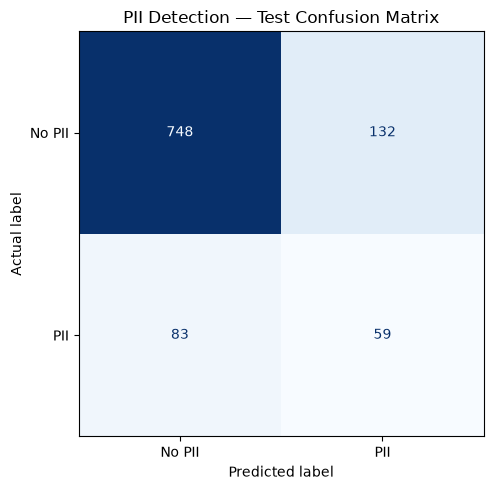

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    identity_test["has_pii"],
    test_pii_predictions,
    labels=[0, 1],
    display_labels=["No PII", "PII"],
    values_format="d",
    cmap=plt.cm.Blues,
    colorbar=False,
    ax=ax
)

ax.set_title("PII Detection — Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

## Save the PII Model

We will save the trained classifier, TF-IDF vectorizer, and validation-selected cutoff together so they can be reused.

In [20]:
import joblib

identity_bundle = {
    "model": identity_model,
    "vectorizer": identity_vectorizer,
    "threshold": identity_threshold,
    "label_mapping": {
        "No PII detected": 0,
        "PII detected": 1
    }
}

joblib.dump(identity_bundle, "identity_pii_model.joblib")

print("PII model saved.")

PII model saved.
